## Подключение к базе

In [10]:
import pandas as pd
from getpass import getpass
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
        
password = getpass("Пароль от PostgreSQL: ")

url = URL.create(
    "postgresql+psycopg",
    username="postgres",
    password=password,
    host="localhost",
    port=5432,
    database="cookie_cats_ab",
)
engine = create_engine(url)

print("Попытка подключения...")
df = pd.read_sql("SELECT * FROM cookie_cats LIMIT 5", engine)
    
print("✅ Успех! Данные получены.")
print(df)
print(f"Размер: {df.shape}")

Попытка подключения...
✅ Успех! Данные получены.
   userid  version  sum_gamerounds  retention_1  retention_7
0     116  gate_30               3        False        False
1     337  gate_30              38         True        False
2     377  gate_40             165         True        False
3     483  gate_40               1        False        False
4     488  gate_40             179         True         True
Размер: (5, 5)


## Чтение таблицы в pandas

In [11]:
df = pd.read_sql("SELECT * FROM cookie_cats", engine)
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## Проверка, что всё загрузилось

In [12]:
print(df.shape)
print(df.dtypes)

(90189, 5)
userid            int64
version             str
sum_gamerounds    int64
retention_1        bool
retention_7        bool
dtype: object


## Проверка баланса групп

In [13]:
from scipy.stats import chisquare

counts = df["version"].value_counts()
print(counts)

stat, p_value = chisquare(counts)
print("chi2 =", round(stat, 2))
print("p-value =", round(p_value, 4))

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64
chi2 = 6.9
p-value = 0.0086


## Убрать выброс

In [14]:
df = df[df["sum_gamerounds"] < 10000].copy()
print(df.shape)

(90188, 5)


## Подсчет процента вернувшихся

In [15]:
retention = df.groupby("version")[["retention_1", "retention_7"]].mean()
print((retention * 100).round(2))

         retention_1  retention_7
version                          
gate_30        44.82        19.02
gate_40        44.23        18.20


## Значима ли разница

In [16]:
from statsmodels.stats.proportion import proportions_ztest

for col in ["retention_1", "retention_7"]:
    g30 = df[df["version"] == "gate_30"][col]
    g40 = df[df["version"] == "gate_40"][col]

    successes = [g30.sum(), g40.sum()]
    nobs = [len(g30), len(g40)]

    z, p = proportions_ztest(successes, nobs)
    print(col, "| z =", round(z, 2), "| p =", round(p, 4))

retention_1 | z = 1.79 | p = 0.0739
retention_7 | z = 3.16 | p = 0.0016


## График удержания

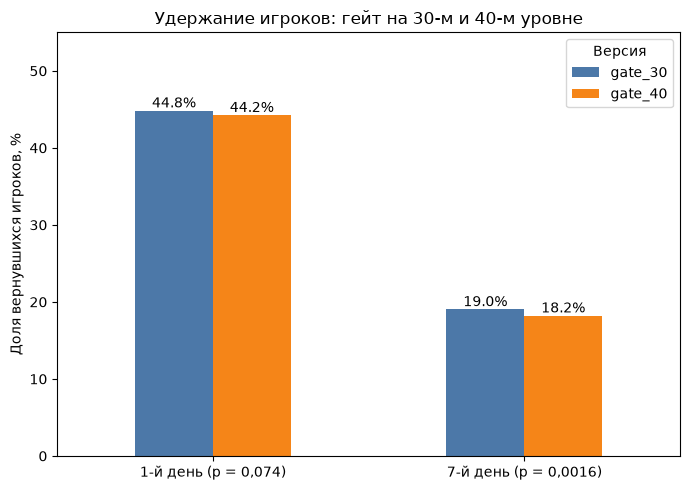

In [18]:
import os
import matplotlib.pyplot as plt

retention_pct = df.groupby("version")[["retention_1", "retention_7"]].mean() * 100
retention_pct.index.name = None
plot_data = retention_pct.T
plot_data.index = ["1-й день (p = 0,074)", "7-й день (p = 0,0016)"]

ax = plot_data.plot(kind="bar", figsize=(7, 5), rot=0, color=["#4C78A8", "#F58518"])

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

ax.set_title("Удержание игроков: гейт на 30-м и 40-м уровне")
ax.set_ylabel("Доля вернувшихся игроков, %")
ax.set_ylim(0, 55)
ax.legend(title="Версия")

plt.tight_layout()
os.makedirs("../images", exist_ok=True)
plt.savefig("../images/retention.png", dpi=150)
plt.show()

## Сегменты по активности

In [19]:
bins = [-1, 0, 9, 49, 99, df["sum_gamerounds"].max()]
labels = ["0", "1-9", "10-49", "50-99", "100+"]
df["segment"] = pd.cut(df["sum_gamerounds"], bins=bins, labels=labels)

seg = df.groupby(["segment", "version"], observed=True).agg(
    players=("userid", "count"),
    ret_1=("retention_1", "mean"),
    ret_7=("retention_7", "mean"),
)
seg[["ret_1", "ret_7"]] = (seg[["ret_1", "ret_7"]] * 100).round(2)
print(seg)

                 players  ret_1  ret_7
segment version                       
0       gate_30     1937   2.12   0.83
        gate_40     2057   2.24   0.63
1-9     gate_30    14898  11.59   1.81
        gate_40    15345  11.62   1.82
10-49   gate_30    16536  51.55  11.44
        gate_40    16251  50.70  10.29
50-99   gate_30     5161  80.95  37.53
        gate_40     5488  79.23  32.89
100+    gate_30     6167  90.22  71.14
        gate_40     6348  89.82  71.03


## Тест для каждого сегмента (significant_corrected - Поправка Бонферрони)

In [20]:
from statsmodels.stats.proportion import proportions_ztest

rows = []
for seg_name in df["segment"].cat.categories:
    part = df[df["segment"] == seg_name]
    g30 = part[part["version"] == "gate_30"]
    g40 = part[part["version"] == "gate_40"]

    for col in ["retention_1", "retention_7"]:
        z, p = proportions_ztest(
            [g30[col].sum(), g40[col].sum()],
            [len(g30), len(g40)],
        )
        rows.append({"segment": seg_name, "metric": col, "p_value": p})

res = pd.DataFrame(rows)
res["significant_0.05"] = res["p_value"] < 0.05
res["significant_corrected"] = res["p_value"] < 0.05 / len(res)
print(res.to_string(float_format=lambda x: f"{x:.2g}"))

  segment       metric  p_value  significant_0.05  significant_corrected
0       0  retention_1      0.8             False                  False
1       0  retention_7     0.47             False                  False
2     1-9  retention_1     0.94             False                  False
3     1-9  retention_7      0.9             False                  False
4   10-49  retention_1     0.13             False                  False
5   10-49  retention_7   0.0008              True                   True
6   50-99  retention_1    0.026              True                  False
7   50-99  retention_7  5.3e-07              True                   True
8    100+  retention_1     0.46             False                  False
9    100+  retention_7      0.9             False                  False
